In [1]:
# Experiment 9: Markov Model and Reinforcement Learning

import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)

# Grid size: 4 x 4
ROWS, COLS = 4, 4

START = (0, 0)
GOAL = (3, 3)
DANGER = (1, 2)

# Actions: Up, Down, Left, Right
ACTIONS = {
    0: (-1, 0),
    1: (1, 0),
    2: (0, -1),
    3: (0, 1)
}

ACTION_NAMES = {
    0: "Up",
    1: "Down",
    2: "Left",
    3: "Right"
}

# Rewards
STEP_REWARD = -1
GOAL_REWARD = 10
DANGER_REWARD = -10

# Transition probabilities
INTENDED_PROB = 0.8
SLIP_PROB = 0.1

print("Environment initialized successfully!")
print("Start:", START, "| Goal:", GOAL, "| Danger:", DANGER)
print("Actions:", list(ACTION_NAMES.values()))

Environment initialized successfully!
Start: (0, 0) | Goal: (3, 3) | Danger: (1, 2)
Actions: ['Up', 'Down', 'Left', 'Right']


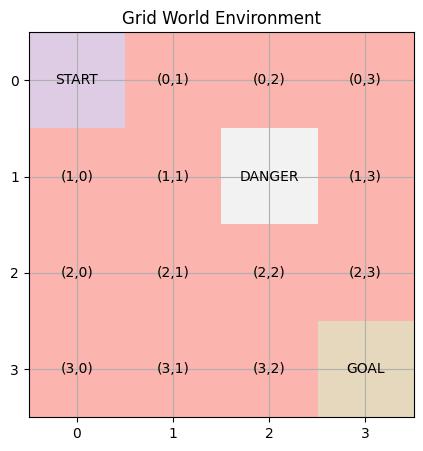

In [2]:
# Environment transition and reward functions

STATES = [
    (r, c)
    for r in range(ROWS)
    for c in range(COLS)
]

def move(state, action):
    """Apply one action, keeping the agent inside the grid."""
    dr, dc = ACTIONS[action]
    r, c = state

    nr = max(0, min(ROWS - 1, r + dr))
    nc = max(0, min(COLS - 1, c + dc))

    return (nr, nc)


def get_next_state(state, action):
    """Stochastic transition: intended direction or sideways slip."""
    r = random.random()

    # Perpendicular actions depend on the chosen direction
    if action in (0, 1):  # Up or Down
        alternatives = [2, 3]  # Left or Right
    else:                 # Left or Right
        alternatives = [0, 1]  # Up or Down

    if r < INTENDED_PROB:
        actual_action = action
    elif r < INTENDED_PROB + SLIP_PROB:
        actual_action = alternatives[0]
    else:
        actual_action = alternatives[1]

    return move(state, actual_action)


def get_reward(next_state):
    if next_state == GOAL:
        return GOAL_REWARD
    elif next_state == DANGER:
        return DANGER_REWARD
    else:
        return STEP_REWARD


def is_terminal(state):
    return state == GOAL or state == DANGER


def reset_environment():
    return START


def display_grid():
    grid = np.zeros((ROWS, COLS))

    for r, c in STATES:
        if (r, c) == START:
            grid[r, c] = 1
        elif (r, c) == GOAL:
            grid[r, c] = 2
        elif (r, c) == DANGER:
            grid[r, c] = 3

    plt.figure(figsize=(5, 5))
    plt.imshow(grid, cmap="Pastel1", vmin=0, vmax=3)

    for r in range(ROWS):
        for c in range(COLS):
            label = f"({r},{c})"
            if (r, c) == START:
                label = "START"
            elif (r, c) == GOAL:
                label = "GOAL"
            elif (r, c) == DANGER:
                label = "DANGER"

            plt.text(c, r, label, ha="center", va="center")

    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title("Grid World Environment")
    plt.grid(True)
    plt.show()


display_grid()

In [3]:
# Exercise 1A: Transition probabilities for a fixed state/action

state = (1, 1)
action = 3  # Right

perpendicular_actions = [0, 1]

possible_transitions = [
    (move(state, action), INTENDED_PROB),
    (move(state, perpendicular_actions[0]), SLIP_PROB),
    (move(state, perpendicular_actions[1]), SLIP_PROB)
]

print(f"Current state: {state}")
print(f"Chosen action: {ACTION_NAMES[action]}")
print("\nPossible next states:")

for next_state, probability in possible_transitions:
    print(f"{next_state}: {probability:.1f}")

print("\nTotal probability:", sum(p for _, p in possible_transitions))

Current state: (1, 1)
Chosen action: Right

Possible next states:
(1, 2): 0.8
(0, 1): 0.1
(2, 1): 0.1

Total probability: 1.0


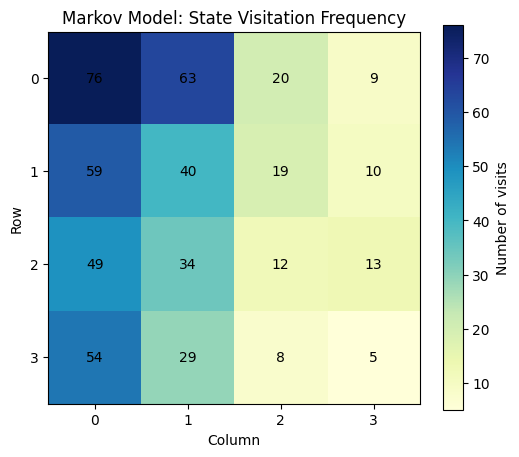

Total simulated transitions: 500
Most visited state: (0, 0)


In [4]:
# Exercise 1B: Random-walk simulation

SIMULATION_STEPS = 500

state = START
visit_counts = np.zeros((ROWS, COLS), dtype=int)
state_history = [state]

for _ in range(SIMULATION_STEPS):
    if is_terminal(state):
        state = START

    action = random.choice(list(ACTIONS.keys()))
    state = get_next_state(state, action)

    visit_counts[state] += 1
    state_history.append(state)

# Plot the state visitation frequencies
plt.figure(figsize=(6, 5))
plt.imshow(visit_counts, cmap="YlGnBu")
plt.colorbar(label="Number of visits")

for r in range(ROWS):
    for c in range(COLS):
        plt.text(
            c, r, str(visit_counts[r, c]),
            ha="center", va="center"
        )

plt.title("Markov Model: State Visitation Frequency")
plt.xlabel("Column")
plt.ylabel("Row")
plt.xticks(range(COLS))
plt.yticks(range(ROWS))
plt.show()

print("Total simulated transitions:", SIMULATION_STEPS)
print("Most visited state:", STATES[np.argmax(visit_counts)])

In [5]:
# Exercise 2: Compare reward settings

def reward_for_settings(next_state, goal_reward, danger_reward, step_reward):
    if next_state == GOAL:
        return goal_reward
    elif next_state == DANGER:
        return danger_reward
    return step_reward


def choose_immediate_reward_action(state, goal_reward, danger_reward,
                                   step_reward):
    """Choose the action with the best expected immediate reward."""
    scores = {}

    for action in ACTIONS:
        if action in (0, 1):
            alternatives = [2, 3]
        else:
            alternatives = [0, 1]

        outcomes = [
            (move(state, action), INTENDED_PROB),
            (move(state, alternatives[0]), SLIP_PROB),
            (move(state, alternatives[1]), SLIP_PROB)
        ]

        expected_reward = sum(
            probability * reward_for_settings(
                next_state, goal_reward, danger_reward, step_reward
            )
            for next_state, probability in outcomes
        )

        scores[action] = expected_reward

    best_action = max(scores, key=scores.get)
    return best_action, scores


test_state = (1, 1)

# Scenario A: Strong penalty for danger
action_a, scores_a = choose_immediate_reward_action(
    test_state, goal_reward=10, danger_reward=-10, step_reward=-1
)

# Scenario B: Danger penalty is removed
action_b, scores_b = choose_immediate_reward_action(
    test_state, goal_reward=10, danger_reward=0, step_reward=-1
)

print("Current state:", test_state)

print("\nScenario A: Danger penalty = -10")
for a, score in scores_a.items():
    print(f"{ACTION_NAMES[a]}: expected immediate reward = {score:.2f}")
print("Selected action:", ACTION_NAMES[action_a])

print("\nScenario B: Danger penalty = 0")
for a, score in scores_b.items():
    print(f"{ACTION_NAMES[a]}: expected immediate reward = {score:.2f}")
print("Selected action:", ACTION_NAMES[action_b])

Current state: (1, 1)

Scenario A: Danger penalty = -10
Up: expected immediate reward = -1.90
Down: expected immediate reward = -1.90
Left: expected immediate reward = -1.00
Right: expected immediate reward = -8.20
Selected action: Left

Scenario B: Danger penalty = 0
Up: expected immediate reward = -0.90
Down: expected immediate reward = -0.90
Left: expected immediate reward = -1.00
Right: expected immediate reward = -0.20
Selected action: Right


In [6]:
# Exercise 3: Q-learning

STATE_TO_INDEX = {state: i for i, state in enumerate(STATES)}

def train_q_learning(
    episodes=3000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.2,
    epsilon_decay=0.999,
    min_epsilon=0.02,
    goal_reward=10,
    danger_reward=-10,
    step_reward=-1,
    seed=42
):
    rng = random.Random(seed)
    Q = np.zeros((len(STATES), len(ACTIONS)))
    episode_rewards = []
    episode_steps = []
    episode_success = []

    for episode in range(episodes):
        state = START
        total_reward = 0
        steps = 0

        # Gradually reduce exploration
        current_epsilon = max(
            min_epsilon,
            epsilon * (epsilon_decay ** episode)
        )

        while not is_terminal(state) and steps < 100:
            s_idx = STATE_TO_INDEX[state]

            # Epsilon-greedy action selection
            if rng.random() < current_epsilon:
                action = rng.choice(list(ACTIONS.keys()))
            else:
                best_actions = np.flatnonzero(
                    Q[s_idx] == np.max(Q[s_idx])
                )
                action = int(rng.choice(list(best_actions)))

            next_state = get_next_state(state, action)

            # Compute reward using configurable settings
            reward = reward_for_settings(
                next_state, goal_reward, danger_reward, step_reward
            )

            ns_idx = STATE_TO_INDEX[next_state]

            # No future value after reaching a terminal state
            if is_terminal(next_state):
                target = reward
            else:
                target = reward + gamma * np.max(Q[ns_idx])

            Q[s_idx, action] += alpha * (
                target - Q[s_idx, action]
            )

            total_reward += reward
            steps += 1
            state = next_state

        episode_rewards.append(total_reward)
        episode_steps.append(steps)
        episode_success.append(state == GOAL)

    return Q, episode_rewards, episode_steps, episode_success


Q, rewards_history, steps_history, success_history = train_q_learning()

print("Q-learning completed!")
print("Q-table shape:", Q.shape)
print("Number of episodes:", len(rewards_history))
print("Average reward over final 100 episodes:",
      round(np.mean(rewards_history[-100:]), 2))
print("Success rate over final 100 episodes:",
      f"{np.mean(success_history[-100:]) * 100:.1f}%")

Q-learning completed!
Q-table shape: (16, 4)
Number of episodes: 3000
Average reward over final 100 episodes: 3.04
Success rate over final 100 episodes: 99.0%


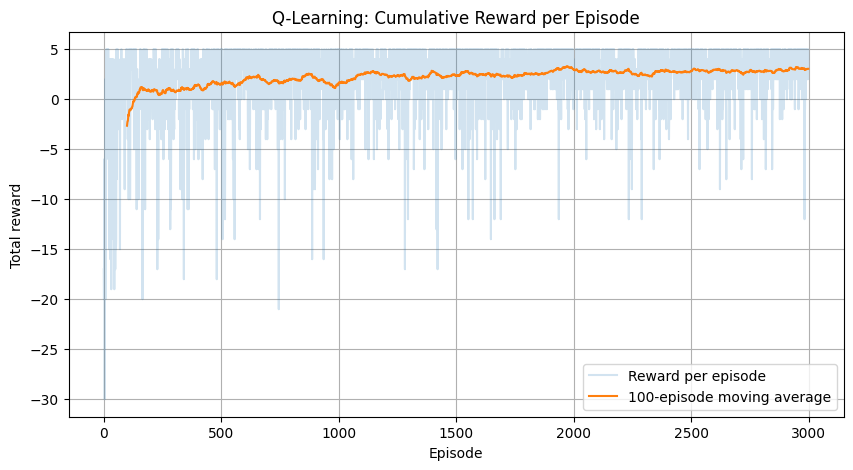

In [7]:
# Exercise 3: Learning curve

def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)

    if len(values) < window:
        return values

    return np.convolve(
        values, np.ones(window) / window, mode="valid"
    )


plt.figure(figsize=(10, 5))

plt.plot(
    rewards_history,
    alpha=0.2,
    label="Reward per episode"
)

smoothed_rewards = moving_average(rewards_history, 100)

plt.plot(
    range(99, len(rewards_history)),
    smoothed_rewards,
    label="100-episode moving average"
)

plt.title("Q-Learning: Cumulative Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.legend()
plt.grid(True)
plt.show()

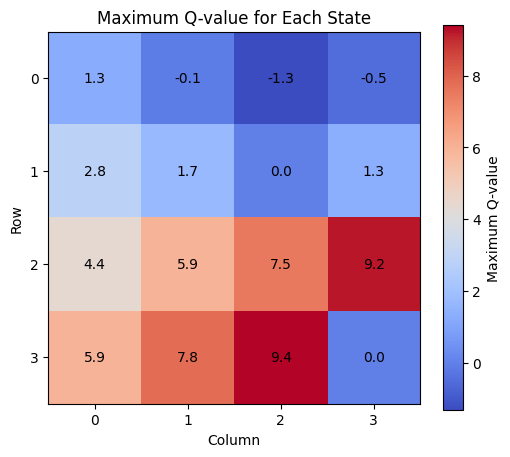

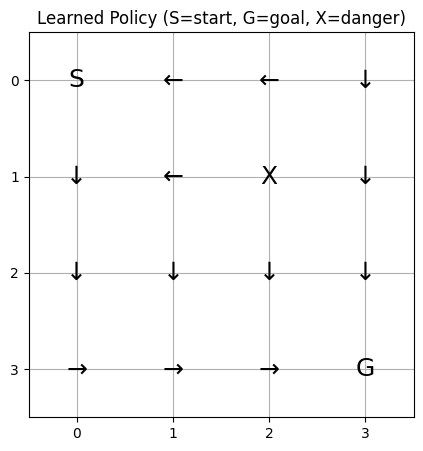

In [8]:
# Exercise 3: Q-value heatmap and learned policy

Q_grid = np.max(Q, axis=1).reshape(ROWS, COLS)

plt.figure(figsize=(6, 5))
plt.imshow(Q_grid, cmap="coolwarm")
plt.colorbar(label="Maximum Q-value")

for r in range(ROWS):
    for c in range(COLS):
        plt.text(c, r, f"{Q_grid[r, c]:.1f}",
                 ha="center", va="center")

plt.title("Maximum Q-value for Each State")
plt.xlabel("Column")
plt.ylabel("Row")
plt.xticks(range(COLS))
plt.yticks(range(ROWS))
plt.show()


ARROWS = {
    0: "↑",
    1: "↓",
    2: "←",
    3: "→"
}

plt.figure(figsize=(6, 5))
plt.imshow(np.zeros((ROWS, COLS)), cmap="Greys", vmin=0, vmax=1)

for state in STATES:
    r, c = state

    if state == START:
        label = "S"
    elif state == GOAL:
        label = "G"
    elif state == DANGER:
        label = "X"
    else:
        best_action = int(np.argmax(Q[STATE_TO_INDEX[state]]))
        label = ARROWS[best_action]

    plt.text(c, r, label, ha="center", va="center", fontsize=18)

plt.title("Learned Policy (S=start, G=goal, X=danger)")
plt.xticks(range(COLS))
plt.yticks(range(ROWS))
plt.grid(True)
plt.show()

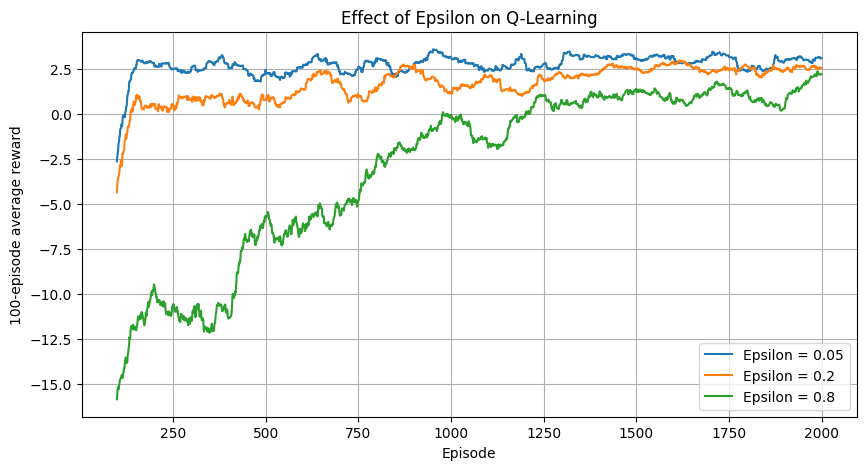

Final 100-episode comparison:
Epsilon=0.05: Reward=3.10, Success=100.0%
Epsilon=0.2: Reward=2.55, Success=99.0%
Epsilon=0.8: Reward=2.22, Success=97.0%


In [9]:
# Exercise 4: Exploration vs exploitation

epsilon_values = [0.05, 0.2, 0.8]
epsilon_results = {}

for eps in epsilon_values:
    Q_eps, reward_eps, steps_eps, success_eps = train_q_learning(
        episodes=2000,
        alpha=0.1,
        gamma=0.95,
        epsilon=eps,
        epsilon_decay=0.999,
        min_epsilon=0.02,
        seed=42
    )

    epsilon_results[eps] = {
        "Q": Q_eps,
        "rewards": reward_eps,
        "steps": steps_eps,
        "success": success_eps
    }

plt.figure(figsize=(10, 5))

for eps, result in epsilon_results.items():
    smoothed = moving_average(result["rewards"], 100)

    plt.plot(
        range(99, len(result["rewards"])),
        smoothed,
        label=f"Epsilon = {eps}"
    )

plt.title("Effect of Epsilon on Q-Learning")
plt.xlabel("Episode")
plt.ylabel("100-episode average reward")
plt.legend()
plt.grid(True)
plt.show()

print("Final 100-episode comparison:")
for eps, result in epsilon_results.items():
    print(
        f"Epsilon={eps}: "
        f"Reward={np.mean(result['rewards'][-100:]):.2f}, "
        f"Success={np.mean(result['success'][-100:]) * 100:.1f}%"
    )

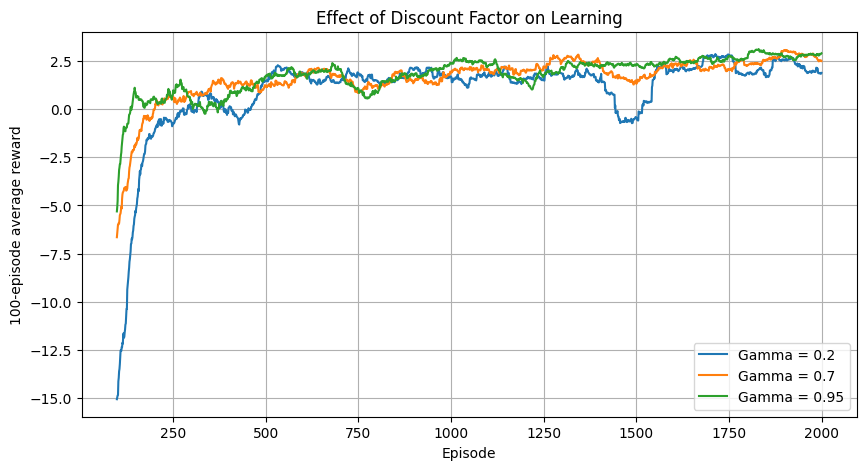

Final 100-episode comparison:
Gamma=0.2: Reward=1.88, Success=98.0%
Gamma=0.7: Reward=2.50, Success=100.0%
Gamma=0.95: Reward=2.90, Success=100.0%


In [10]:
# Exercise 5: Effect of discount factor

gamma_values = [0.2, 0.7, 0.95]
gamma_results = {}

for g in gamma_values:
    Q_g, reward_g, steps_g, success_g = train_q_learning(
        episodes=2000,
        alpha=0.1,
        gamma=g,
        epsilon=0.2,
        epsilon_decay=0.999,
        min_epsilon=0.02,
        seed=42
    )

    gamma_results[g] = {
        "Q": Q_g,
        "rewards": reward_g,
        "steps": steps_g,
        "success": success_g
    }

plt.figure(figsize=(10, 5))

for g, result in gamma_results.items():
    smoothed = moving_average(result["rewards"], 100)

    plt.plot(
        range(99, len(result["rewards"])),
        smoothed,
        label=f"Gamma = {g}"
    )

plt.title("Effect of Discount Factor on Learning")
plt.xlabel("Episode")
plt.ylabel("100-episode average reward")
plt.legend()
plt.grid(True)
plt.show()

print("Final 100-episode comparison:")
for g, result in gamma_results.items():
    print(
        f"Gamma={g}: "
        f"Reward={np.mean(result['rewards'][-100:]):.2f}, "
        f"Success={np.mean(result['success'][-100:]) * 100:.1f}%"
    )

In [11]:
# Exercise 6A: Policy evaluation

def evaluate_policy(Q, episodes=500, max_steps=100):
    episode_returns = []
    episode_lengths = []
    successes = []

    for _ in range(episodes):
        state = START
        total_reward = 0
        steps = 0

        while not is_terminal(state) and steps < max_steps:
            s_idx = STATE_TO_INDEX[state]

            # Greedy policy: choose the best learned action
            action = int(np.argmax(Q[s_idx]))

            next_state = get_next_state(state, action)
            reward = get_reward(next_state)

            total_reward += reward
            steps += 1
            state = next_state

        episode_returns.append(total_reward)
        episode_lengths.append(steps)
        successes.append(state == GOAL)

    return {
        "average_reward": np.mean(episode_returns),
        "average_steps": np.mean(episode_lengths),
        "success_rate": np.mean(successes) * 100
    }


evaluation_results = {}

# Evaluate policies learned under different epsilon values
for eps, result in epsilon_results.items():
    evaluation_results[f"Epsilon={eps}"] = evaluate_policy(
        result["Q"], episodes=500
    )

# Evaluate policies learned under different gamma values
for g, result in gamma_results.items():
    evaluation_results[f"Gamma={g}"] = evaluate_policy(
        result["Q"], episodes=500
    )

print("POLICY EVALUATION")
print("-" * 75)
print(
    f"{'Setting':<18}"
    f"{'Avg Reward':>15}"
    f"{'Avg Steps':>15}"
    f"{'Success Rate':>18}"
)
print("-" * 75)

for setting, metrics in evaluation_results.items():
    print(
        f"{setting:<18}"
        f"{metrics['average_reward']:>15.2f}"
        f"{metrics['average_steps']:>15.2f}"
        f"{metrics['success_rate']:>17.1f}%"
    )

POLICY EVALUATION
---------------------------------------------------------------------------
Setting                Avg Reward      Avg Steps      Success Rate
---------------------------------------------------------------------------
Epsilon=0.05                 3.22           7.42             98.2%
Epsilon=0.2                  2.85           8.07             99.6%
Epsilon=0.8                  3.13           7.35             97.4%
Gamma=0.2                    2.58           8.42            100.0%
Gamma=0.7                    2.85           8.15            100.0%
Gamma=0.95                   2.86           8.10             99.8%


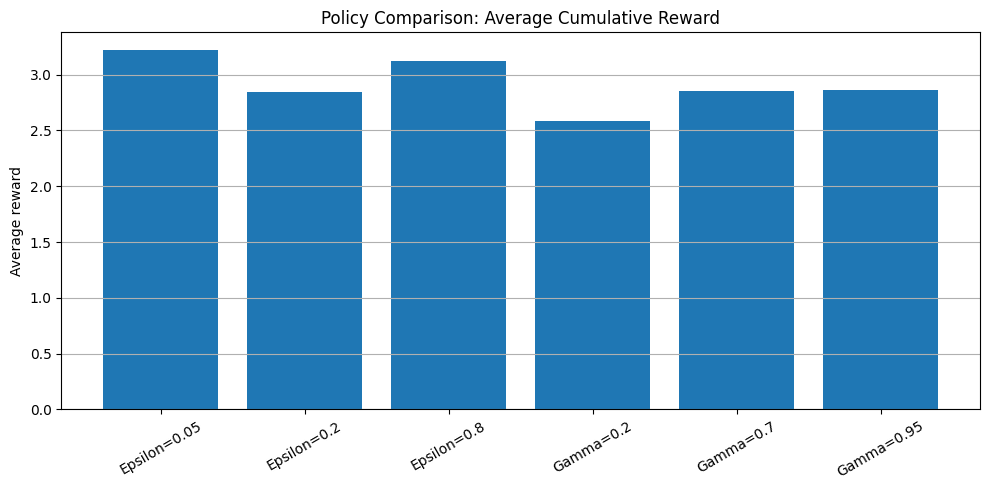

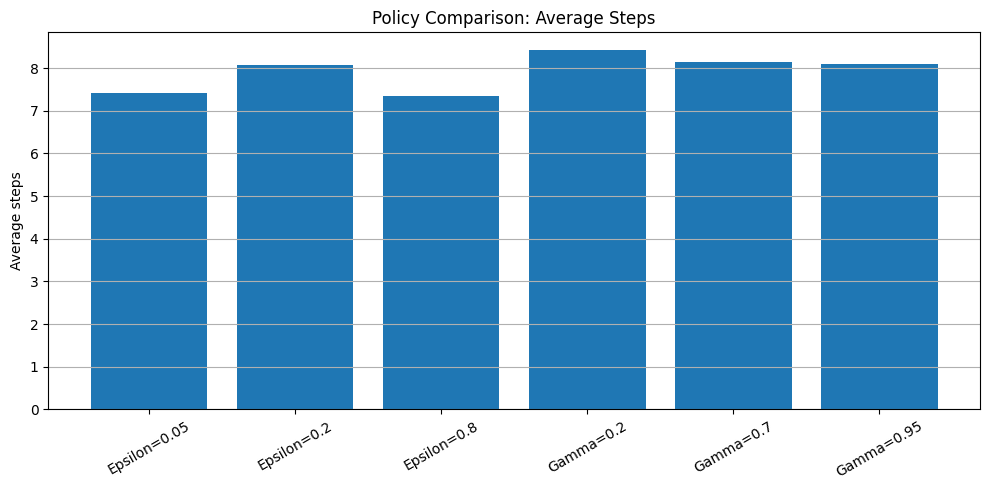

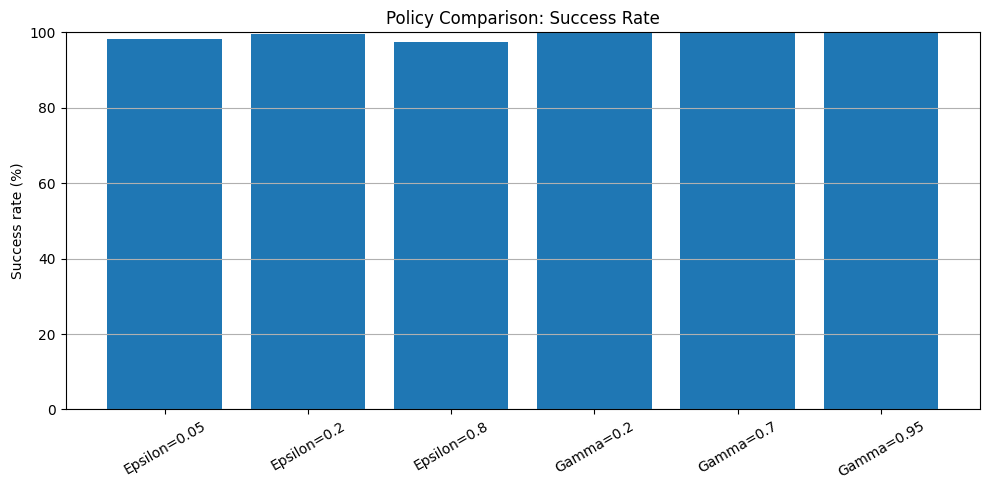

In [12]:
# Exercise 6B: Compare evaluation metrics

settings = list(evaluation_results.keys())

avg_rewards = [
    evaluation_results[s]["average_reward"] for s in settings
]

avg_steps = [
    evaluation_results[s]["average_steps"] for s in settings
]

success_rates = [
    evaluation_results[s]["success_rate"] for s in settings
]

# Average cumulative reward
plt.figure(figsize=(10, 5))
plt.bar(settings, avg_rewards)
plt.title("Policy Comparison: Average Cumulative Reward")
plt.ylabel("Average reward")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# Average steps
plt.figure(figsize=(10, 5))
plt.bar(settings, avg_steps)
plt.title("Policy Comparison: Average Steps")
plt.ylabel("Average steps")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# Success rate
plt.figure(figsize=(10, 5))
plt.bar(settings, success_rates)
plt.title("Policy Comparison: Success Rate")
plt.ylabel("Success rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()